# Performance Benchmarking & Data Analysis
This notebook executes data ingestion, warm-up filtering, statistical aggregation, and visualization export.

Project root: C:\Users\acer\performance-benchmarking-project-main
Raw data: C:\Users\acer\performance-benchmarking-project-main\data\raw\test_run.jsonl

Raw data loaded successfully.
Total records: 210


,method,phase,latency_ms,throughput_rps,peak_memory_mb,success
0,baseline_method,warmup,13.9370,574.011624,0.031414,True
1,baseline_method,warmup,2.7332,2926.972048,0.017968,True
2,baseline_method,warmup,2.3379,3421.874330,0.015933,True
3,baseline_method,warmup,2.2725,3520.352033,0.015489,True
4,baseline_method,warmup,2.3471,3408.461502,0.015382,True



Warm-up measurements: 10
Evaluation measurements: 200

SUMMARY TABLE


,method,observations,latency_mean_ms,latency_median_ms,latency_std_ms,latency_p95_ms,latency_p99_ms,median_ci_lower_ms,median_ci_upper_ms,throughput_mean_rps,memory_mean_mb,error_rate_pct,speedup_vs_baseline
0,baseline_method,100,2.6316,2.5710,0.3498,3.2265,3.7997,2.4898,2.6311,3086.2500,0.0148,0.0,1.0000
1,optimized_method,100,2.0823,1.9952,0.2565,2.4361,3.2609,1.9659,2.0156,3883.8614,0.0122,0.0,1.2886


Summary saved to: C:\Users\acer\performance-benchmarking-project-main\data\processed\metrics_summary.csv


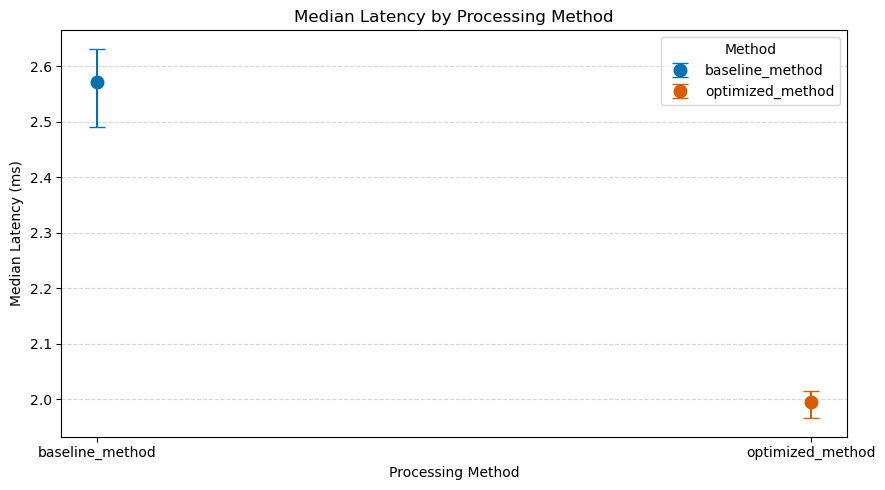

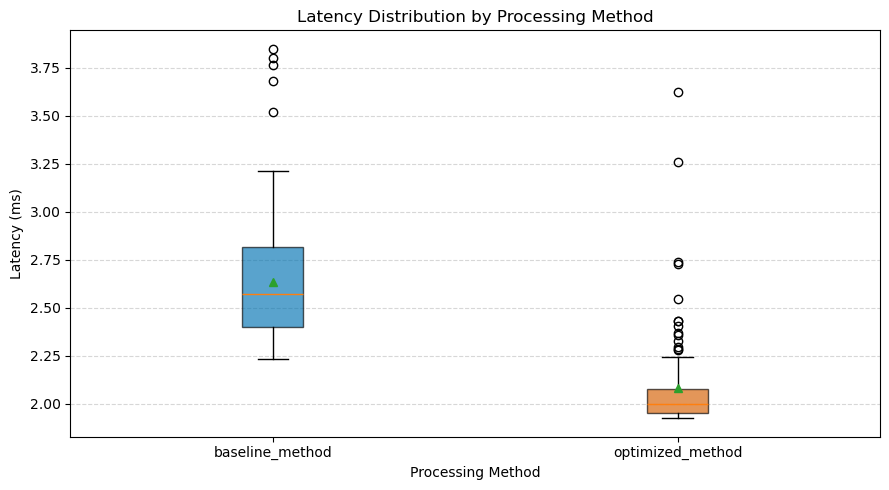


TASK 3 ANALYSIS COMPLETED SUCCESSFULLY!

Generated files:
1. C:\Users\acer\performance-benchmarking-project-main\data\processed\metrics_summary.csv
2. C:\Users\acer\performance-benchmarking-project-main\reports\figures\fig1_latency_comparison.png
3. C:\Users\acer\performance-benchmarking-project-main\reports\figures\fig1_latency_comparison.pdf
4. C:\Users\acer\performance-benchmarking-project-main\reports\figures\fig2_latency_distribution.png
5. C:\Users\acer\performance-benchmarking-project-main\reports\figures\fig2_latency_distribution.pdf

Methods analyzed: ['baseline_method', 'optimized_method']
Evaluation observations: 200
Random seed: 42
Bootstrap samples: 2000
Figure resolution: 300 DPI


In [1]:

# TASK 3 — Data Analysis and Scientific Visualization

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


# 1. PROJECT PATH

ROOT = Path(r"C:\Users\acer\performance-benchmarking-project-main")

if not ROOT.exists():
    raise FileNotFoundError(
        f"Project folder not found: {ROOT}"
    )

raw_path = ROOT / "data" / "raw" / "test_run.jsonl"
processed_dir = ROOT / "data" / "processed"
figures_dir = ROOT / "reports" / "figures"

processed_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Raw data:", raw_path)


# 2. LOAD RAW JSONL DATA

if not raw_path.exists():
    raise FileNotFoundError(
        "test_run.jsonl was not found. Run src/benchmark.py first."
    )

records = []

with open(raw_path, "r", encoding="utf-8") as file:
    for line_number, line in enumerate(file, start=1):
        if line.strip():
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as error:
                raise ValueError(
                    f"Invalid JSON on line {line_number}: {error}"
                )

df_raw = pd.DataFrame(records)

required_columns = [
    "method",
    "phase",
    "latency_ms",
    "throughput_rps",
    "peak_memory_mb",
    "success"
]

missing_columns = [
    col for col in required_columns
    if col not in df_raw.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in JSONL: {missing_columns}"
    )

print("\nRaw data loaded successfully.")
print("Total records:", len(df_raw))

display(df_raw.head())


# 3. FILTER WARM-UP MEASUREMENTS

df = df_raw[df_raw["phase"] == "evaluation"].copy()

if df.empty:
    raise ValueError("No evaluation measurements found.")

df["latency_ms"] = pd.to_numeric(
    df["latency_ms"], errors="coerce"
)

df["throughput_rps"] = pd.to_numeric(
    df["throughput_rps"], errors="coerce"
)

df["peak_memory_mb"] = pd.to_numeric(
    df["peak_memory_mb"], errors="coerce"
)

df = df.dropna(
    subset=["latency_ms", "throughput_rps", "peak_memory_mb"]
)

# Convert success values safely to Boolean
df["success"] = (
    df["success"]
    .astype(str)
    .str.lower()
    .isin(["true", "1", "yes"])
)

if df.empty:
    raise ValueError("No valid evaluation measurements remain.")

print("\nWarm-up measurements:", len(df_raw) - len(df))
print("Evaluation measurements:", len(df))


# 4. DESCRIPTIVE STATISTICS AND 95% CONFIDENCE INTERVAL

# Fixed random seed for reproducibility
rng = np.random.default_rng(42)

def bootstrap_median_ci(values, n_bootstrap=2000):
    values = np.asarray(values, dtype=float)

    bootstrap_medians = []

    for _ in range(n_bootstrap):
        sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )

        bootstrap_medians.append(np.median(sample))

    lower = np.percentile(bootstrap_medians, 2.5)
    upper = np.percentile(bootstrap_medians, 97.5)

    return lower, upper


summary_rows = []

for method, group in df.groupby("method"):

    latency = group["latency_ms"].to_numpy()

    ci_lower, ci_upper = bootstrap_median_ci(latency)

    summary_rows.append({
        "method": method,
        "observations": len(group),
        "latency_mean_ms": latency.mean(),
        "latency_median_ms": np.median(latency),
        "latency_std_ms": np.std(latency, ddof=1),
        "latency_p95_ms": np.percentile(latency, 95),
        "latency_p99_ms": np.percentile(latency, 99),
        "median_ci_lower_ms": ci_lower,
        "median_ci_upper_ms": ci_upper,
        "throughput_mean_rps": group["throughput_rps"].mean(),
        "memory_mean_mb": group["peak_memory_mb"].mean(),
        "error_rate_pct": (
            1 - group["success"].mean()
        ) * 100
    })


summary = pd.DataFrame(summary_rows)


# 5. CALCULATE SPEEDUP

baseline_name = "baseline_method"
optimized_name = "optimized_method"

summary["speedup_vs_baseline"] = np.nan

if (
    baseline_name in summary["method"].values
    and optimized_name in summary["method"].values
):

    baseline_latency = summary.loc[
        summary["method"] == baseline_name,
        "latency_median_ms"
    ].iloc[0]

    optimized_latency = summary.loc[
        summary["method"] == optimized_name,
        "latency_median_ms"
    ].iloc[0]

    summary.loc[
        summary["method"] == baseline_name,
        "speedup_vs_baseline"
    ] = 1.0

    summary.loc[
        summary["method"] == optimized_name,
        "speedup_vs_baseline"
    ] = baseline_latency / optimized_latency

else:
    print(
        "\nWarning: Expected method names were not found."
    )
    print("Available methods:", summary["method"].tolist())


# 6. SAVE SUMMARY CSV

summary_path = processed_dir / "metrics_summary.csv"

summary.to_csv(
    summary_path,
    index=False,
    float_format="%.4f"
)

print("\nSUMMARY TABLE")
display(summary.round(4))

print("Summary saved to:", summary_path)


# 7. SCIENTIFIC VISUALIZATION — FIGURE 1
# Median latency with 95% bootstrap confidence intervals

methods = summary["method"].tolist()

x = np.arange(len(methods))

medians = summary["latency_median_ms"].to_numpy()

lower_errors = (
    medians - summary["median_ci_lower_ms"].to_numpy()
)

upper_errors = (
    summary["median_ci_upper_ms"].to_numpy() - medians
)

colors = ["#0072B2", "#D55E00"]

fig, ax = plt.subplots(figsize=(9, 5))

for i in range(len(methods)):
    ax.errorbar(
        x[i],
        medians[i],
        yerr=[
            [lower_errors[i]],
            [upper_errors[i]]
        ],
        fmt="o",
        markersize=9,
        capsize=6,
        color=colors[i % len(colors)],
        label=methods[i]
    )

ax.set_xticks(x)
ax.set_xticklabels(methods)

ax.set_title("Median Latency by Processing Method")
ax.set_xlabel("Processing Method")
ax.set_ylabel("Median Latency (ms)")

ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(title="Method")

fig.tight_layout()

fig1_png = figures_dir / "fig1_latency_comparison.png"
fig1_pdf = figures_dir / "fig1_latency_comparison.pdf"

fig.savefig(fig1_png, dpi=300, bbox_inches="tight")
fig.savefig(fig1_pdf, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)


# 8. SCIENTIFIC VISUALIZATION — FIGURE 2
# Distribution of raw evaluation latency

fig, ax = plt.subplots(figsize=(9, 5))

box_data = [
    df.loc[
        df["method"] == method,
        "latency_ms"
    ].to_numpy()
    for method in methods
]

box = ax.boxplot(
    box_data,
    patch_artist=True,
    tick_labels=methods,
    showmeans=True
)


for i, patch in enumerate(box["boxes"]):
    patch.set_facecolor(colors[i % len(colors)])
    patch.set_alpha(0.65)

ax.set_title("Latency Distribution by Processing Method")
ax.set_xlabel("Processing Method")
ax.set_ylabel("Latency (ms)")

ax.grid(axis="y", linestyle="--", alpha=0.5)

fig.tight_layout()

fig2_png = figures_dir / "fig2_latency_distribution.png"
fig2_pdf = figures_dir / "fig2_latency_distribution.pdf"

fig.savefig(fig2_png, dpi=300, bbox_inches="tight")
fig.savefig(fig2_pdf, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)


# 9. FINAL RESULTS

print("\nTASK 3 ANALYSIS COMPLETED SUCCESSFULLY!")

print("\nGenerated files:")

print("1.", summary_path)
print("2.", fig1_png)
print("3.", fig1_pdf)
print("4.", fig2_png)
print("5.", fig2_pdf)

print("\nMethods analyzed:", methods)
print("Evaluation observations:", len(df))
print("Random seed: 42")
print("Bootstrap samples: 2000")
print("Figure resolution: 300 DPI")


In [2]:
from pathlib import Path

print(Path.cwd())
print(Path("01_data_analysis.ipynb").resolve())

C:\Users\acer
C:\Users\acer\01_data_analysis.ipynb
